# Aprendizado não supervisionado

**Objetivo deste notebook:** Compreender o aprendizado sem rótulos e reconhecer situações de exploração de padrões nos dados.


O aprendizado não supervisionado também é um tipo comum de aprendizado de máquina. Ele difere do aprendizado supervisionado pelo fato de que os dados não são rotulados. Em outras palavras, o objetivo de um modelo de aprendizado de máquina é extrair o máximo de informações possível de um conjunto de dados que não possui rótulos ou alvos para prever.

Mesmo sem rótulos, ainda podemos extrair muitas informações de um conjunto de dados não rotulado. Por exemplo, vamos voltar ao exemplo dos gatos e cachorros que não possui rótulos. Não sabemos que tipo de animal cada imagem representa, então não podemos prever se uma nova imagem corresponde a um cachorro ou a um gato. No entanto, podemos fazer outras coisas, como determinar se duas imagens são semelhantes ou diferentes. Um algoritmo de aprendizado não supervisionado pode agrupar as imagens com base na similaridade, mesmo sem saber o que cada grupo representa. Se feito corretamente, o algoritmo poderia separar as imagens de cachorros das de gatos, ou até mesmo agrupar cada um deles por raça.

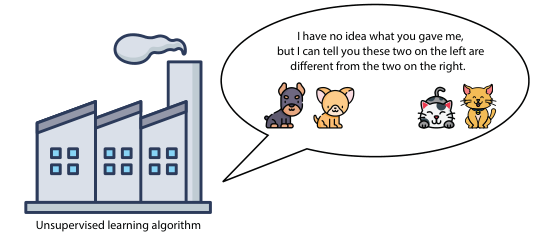

De fato, mesmo que os rótulos estejam presentes, ainda podemos usar técnicas de aprendizado não supervisionado em nossos dados para pré-processá-los e aplicar métodos de aprendizado supervisionado de forma mais eficaz.

Os principais ramos do aprendizado não supervisionado são:

- **Algoritmos de agrupamento (clustering)**: Algoritmos que agrupam dados em clusters com base na similaridade.
- **Algoritmos de redução de dimensionalidade**: Algoritmos que simplificam nossos dados e os descrevem fielmente com menos características.
- **Algoritmos generativos**: Algoritmos que podem gerar novos pontos de dados que se assemelham aos dados existentes.

## Algoritmos de clustering

Como vimos anteriormente, algoritmos de agrupamento são aqueles que dividem o conjunto de dados em grupos similares. Para ilustrar isso, vamos voltar aos dois conjuntos de dados vistos em "Aprendizado supervisionado" — o conjunto de dados de habitação e o conjunto de dados de e-mails de spam — mas imagine que eles não têm rótulos. Isso significa que o conjunto de dados de habitação não tem preços, e o conjunto de dados de e-mails não tem informações sobre os e-mails serem spam ou não.

Vamos começar com o conjunto de dados de habitação. Podemos, de alguma forma, agrupar as casas por similaridade. Por exemplo, poderíamos agrupá-las por localização, preço, tamanho ou uma combinação desses fatores. Esse processo é chamado de agrupamento (clustering). Clustering é um ramo do aprendizado de máquina não supervisionado que consiste em tarefas que agrupam os elementos do nosso conjunto de dados em clusters onde todos os pontos de dados são semelhantes.

Agora vamos olhar para o conjunto de dados de e-mails. Como o conjunto de dados não é rotulado, não sabemos se cada e-mail é spam ou não. No entanto, ainda podemos aplicar algum agrupamento ao nosso conjunto de dados. Um algoritmo de clustering divide nossos e-mails em alguns grupos diferentes com base em diferentes características do e-mail. Essas características podem ser as palavras na mensagem, o remetente, o número e o tamanho dos anexos ou os tipos de links dentro do e-mail. Após o agrupamento do conjunto de dados, um humano (ou uma combinação de um humano e um algoritmo de aprendizado supervisionado) poderia rotular esses clusters por categorias como "Pessoal", "Social" e "Promoções".


In [3]:
import pandas as pd
import seaborn as sns

emails = {
    "tamanho kb": [8, 12, 43, 10, 40, 25, 23, 28, 26],
    "recipientes": [1, 1, 1, 2, 2, 5, 6, 6, 7]
}

df_emails = pd.DataFrame(emails)

df_emails

,tamanho kb,recipientes
0,8,1
1,12,1
2,43,1
3,10,2
4,40,2
5,25,5
6,23,6
7,28,6
8,26,7


Parece que poderíamos agrupar os e-mails pelo número de destinatários. Isso resultaria em dois clusters: um com e-mails contendo dois ou menos destinatários, e outro com e-mails contendo cinco ou mais destinatários. Também poderíamos tentar agrupá-los em três grupos por tamanho. Mas, à medida que a tabela fica maior e maior, identificar os grupos visualmente se torna cada vez mais difícil.


<Axes: xlabel='tamanho kb', ylabel='recipientes'>

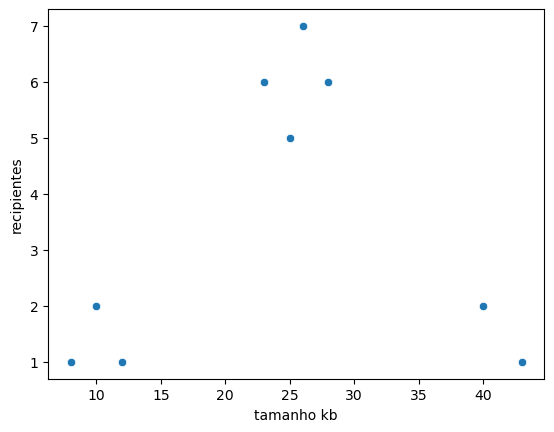

In [ ]:
sns.scatterplot(x="tamanho kb", y="recipientes", data=df_emails)

Imagine se nossos dados contivessem milhões de pontos, com centenas ou milhares de características. Com mais de três características, é impossível para os humanos verem os clusters, porque estariam em dimensões que não podemos visualizar. Felizmente, computadores podem fazer esse tipo de agrupamento para grandes conjuntos de dados com múltiplas linhas e colunas.

Outras aplicações de clustering são as seguintes:

- **Segmentação de mercado**: dividir os clientes em grupos com base em dados demográficos e comportamento de compras anterior para criar diferentes estratégias de marketing para os grupos.
- **Genética**: agrupar espécies em grupos com base na similaridade genética.
- **Imagem médica**: dividir uma imagem em diferentes partes para estudar diferentes tipos de tecido.
- **Recomendações de vídeos**: dividir os usuários em grupos com base em dados demográficos e vídeos assistidos anteriormente e usar isso para recomendar a um usuário os vídeos que outros usuários em seu grupo assistiram.

Aqui estão alguns dos algoritmos de clustering mais importantes:

- **Clustering K-means**: esse algoritmo agrupa pontos escolhendo alguns centros de massa aleatórios e movendo-os cada vez mais perto dos pontos até que estejam nos lugares certos.
- **Clustering hierárquico**: esse algoritmo começa agrupando os pontos mais próximos e continua dessa forma até termos alguns grupos bem definidos.
- **Clustering baseado em densidade (DBSCAN)**: esse algoritmo começa agrupando pontos juntos em lugares com alta densidade, enquanto rotula os pontos isolados como ruído.
- **Modelos de mistura gaussiana**: esse algoritmo não atribui um ponto a um cluster, mas em vez disso, atribui frações do ponto a cada um dos clusters existentes. Por exemplo, se houver três clusters, A, B e C, então o algoritmo poderia determinar que 60% de um ponto específico pertence ao grupo A, 25% ao grupo B e 15% ao grupo C.


## Redução de dimensionalidade simplifica dados sem perder muita informação

A redução de dimensionalidade é um passo de pré-processamento útil que podemos aplicar para simplificar vastamente nossos dados antes de aplicar outras técnicas. Como exemplo, vamos voltar ao conjunto de dados de habitação. Imagine que as características são as seguintes:

- Tamanho
- Número de quartos
- Número de banheiros
- Taxa de criminalidade no bairro
- Distância até a escola mais próxima

Esse conjunto de dados tem cinco colunas de dados.Você vê alguma maneira de simplificá-las — talvez agrupá-las em algumas categorias menores e mais gerais?

Podemos ver que as três primeiras características são semelhantes, porque todas estão relacionadas ao tamanho da casa. Da mesma forma, a quarta e a quinta características são semelhantes entre si, porque estão relacionadas à qualidade do bairro. Poderíamos condensar as três primeiras características em uma grande característica de "tamanho" e a quarta e a quinta em uma grande característica de "qualidade do bairro". 

Como condensar as características de tamanho? Poderíamos esquecer os cômodos e quartos e considerar apenas o tamanho, poderíamos somar o número de quartos e banheiros ou talvez considerar alguma outra combinação das três características. Também poderíamos condensar as características de qualidade da área de maneiras semelhantes. 

Os algoritmos de redução de dimensionalidade encontrarão boas maneiras de condensar essas características, perdendo o mínimo de informação possível e mantendo nossos dados o mais intactos possível, ao mesmo tempo que simplificam para facilitar o processamento e o armazenamento.

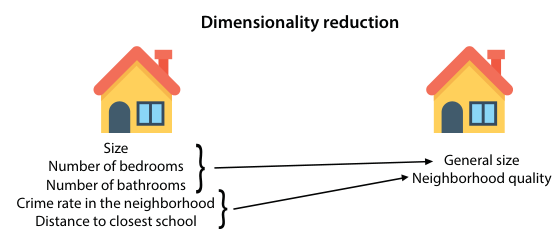

Por que o nome "redução de dimensionalidade"? O número de features (ou colunas) em um conjunto de dados é chamado de dimensionalidade. Portanto, a redução de dimensionalidade é o processo de reduzir o número de colunas em um conjunto de dados. A redução de dimensionalidade é útil porque:

- **Facilita a visualização**: é muito mais fácil visualizar dados em duas ou três dimensões do que em dezenas ou centenas dimensões.
- **Reduz o tempo de treinamento**: modelos de aprendizado de máquina treinam mais rapidamente em conjuntos de dados com menos colunas.
- **Reduz o risco de overfitting**: modelos de aprendizado de máquina têm menos chances de memorizar os dados de treinamento se houver menos colunas.
- **Reduz o espaço de armazenamento**: conjuntos de dados com menos colunas ocupam menos espaço em disco.

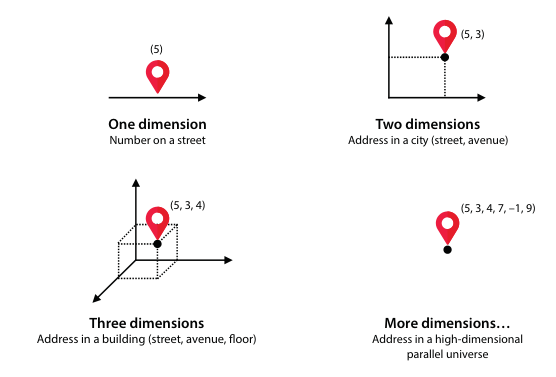

## Aprendizado de máquina generativo

Se você já viu rostos, imagens ou vídeos ultra-realistas criados por computadores, então você já viu o aprendizado de máquina generativo em ação.

O campo do aprendizado generativo consiste em modelos que, dado um conjunto de dados, podem gerar novos pontos de dados que se parecem com amostras desse conjunto de dados original. Esses algoritmos são forçados a aprender como os dados se parecem para produzir pontos de dados semelhantes. Por exemplo, se o conjunto de dados contiver imagens de rostos, então o algoritmo produzirá rostos com aparência realista. Algoritmos generativos têm sido capazes de criar imagens, pinturas e assim por diante tremendamente realistas. Eles também geraram vídeos, músicas, histórias, poesias e muitas outras coisas maravilhosas. O algoritmo generativo mais popular é a rede adversária generativa (GANs), desenvolvida por Ian Goodfellow e seus coautores. Outros algoritmos generativos úteis e populares são autoencoders variacionais, desenvolvidos por Kingma e Welling, e máquinas de Boltzmann restritas (RBMs), desenvolvidas por Geoffrey Hinton.


https://arxiv.org/pdf/1710.10196